# Feature Engineering

In this notebook, we will transform completed team-game records into pregame model features. The most important requirement is that a game's features can only contain information that was available before kickoff.

The feature engineering process is as follows:

1. Calculate five-game, exponentially weighted, and season-to-date team statistics
2. Attach the most recent strictly earlier team snapshot to each game
3. Calculate pregame Elo ratings and rest
4. Add recruiting and talent information
5. Create home-minus-away difference features
6. verify that the feature table does not contain temporal leakage

In [1]:
from pathlib import Path
import sys

# Allow the notebook to run from either the project root or the notebooks folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

## Imports and Data

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from src.config import INTERIM_DIR, PROCESSED_DIR
from src.data import load_interim_data
from src.features import build_modeling_table, check_for_leakage, get_model_features
from src.visualization import COLORS, set_plot_style

pd.set_option('display.max_columns', 150)
set_plot_style()

tables = load_interim_data()
team_games = pd.read_csv(INTERIM_DIR / 'team_games.csv', parse_dates=['start_date'])

## Constructing Pregame Features

In [3]:
modeling_table = build_modeling_table(
    games=tables['games'],
    team_games=team_games,
    talent=tables['talent'],
    recruiting=tables['recruiting'],
    lines=tables['lines'],
)

check_for_leakage(modeling_table)
print('Leakage check passed.')
print('Shape of the modeling table:', modeling_table.shape)

Leakage check passed.
Shape of the modeling table: (9847, 209)


For a game in a given week, `home_last_game_date` and `away_last_game_date` must both be earlier than the target game's kickoff. The automated check above raises an error if this condition is violated.

In [4]:
model_features = get_model_features(modeling_table)

market_features = {'market_margin', 'market_total', 'line_providers'}
assert market_features.isdisjoint(model_features)

print('Statistics-only model features:', len(model_features))
print('Market features included in the original model:', market_features.intersection(model_features))
model_features[:20]

Statistics-only model features: 161
Market features included in the original model: set()


['away_defense_explosiveness_ewm',
 'away_defense_explosiveness_last_5',
 'away_defense_explosiveness_season',
 'away_defense_ppa_ewm',
 'away_defense_ppa_last_5',
 'away_defense_ppa_season',
 'away_defense_success_rate_ewm',
 'away_defense_success_rate_last_5',
 'away_defense_success_rate_season',
 'away_elo',
 'away_fourth_down_pct_ewm',
 'away_fourth_down_pct_last_5',
 'away_fourth_down_pct_season',
 'away_games_played',
 'away_net_passing_yards_ewm',
 'away_net_passing_yards_last_5',
 'away_net_passing_yards_season',
 'away_offense_explosiveness_ewm',
 'away_offense_explosiveness_last_5',
 'away_offense_explosiveness_season']

## Missing Values

In [5]:
feature_missingness = (
    modeling_table[model_features]
    .isna().mean()
    .sort_values(ascending=False)
    .rename('missing proportion')
)

feature_missingness.head(20).to_frame()

,missing proportion
talent_diff,0.079415
away_talent_score,0.078400
home_talent_score,0.078298
diff_fourth_down_pct_season,0.050574
home_fourth_down_pct_season,0.030060
away_fourth_down_pct_season,0.028943
diff_fourth_down_pct_last_5,0.012796
diff_fourth_down_pct_ewm,0.011679
diff_defense_ppa_season,0.010358
diff_defense_success_rate_season,0.010358


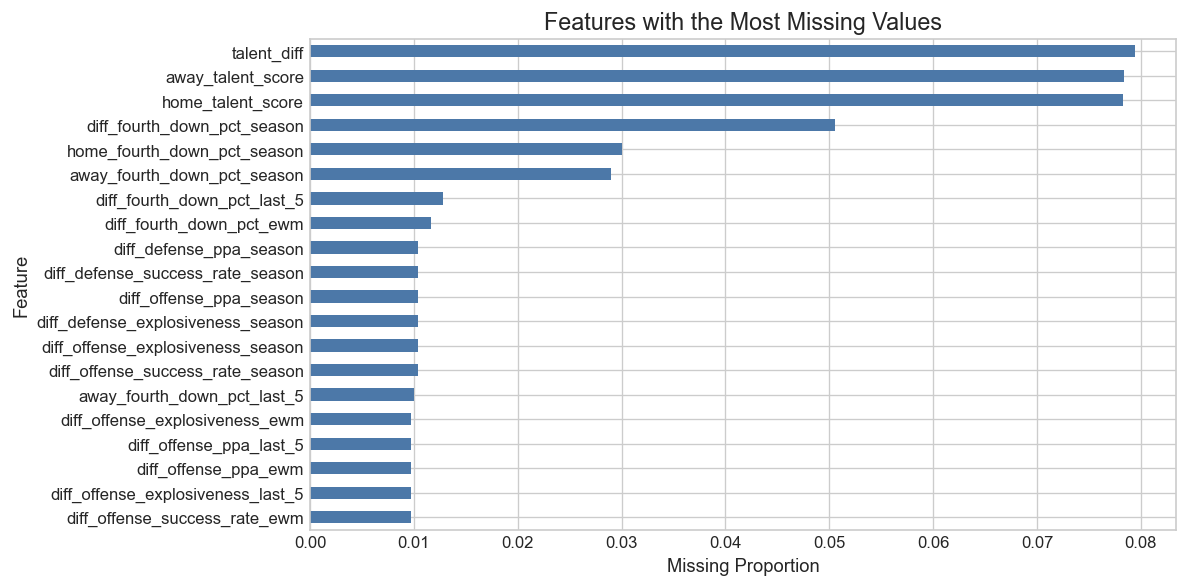

In [6]:
fig, axis = plt.subplots(figsize=(10, 5))
feature_missingness.head(20).sort_values().plot.barh(ax=axis, color=COLORS['blue'])
axis.set(title='Features with the Most Missing Values', xlabel='Missing Proportion', ylabel='Feature')
plt.tight_layout()
plt.show()

## Feature Relationships

In [7]:
completed = modeling_table[modeling_table['completed'].eq(True)].copy()
target_correlations = (
    completed[model_features + ['actual_margin', 'actual_total']]
    .corr(numeric_only=True)[['actual_margin', 'actual_total']]
    .drop(index=['actual_margin', 'actual_total'])
)

print('Features most correlated with margin:')
display(target_correlations['actual_margin'].abs().sort_values(ascending=False).head(12).to_frame())

print('Features most correlated with total:')
display(target_correlations['actual_total'].abs().sort_values(ascending=False).head(12).to_frame())

Features most correlated with margin:


,actual_margin
elo_diff,0.562671
elo_home_win_probability,0.556357
recruiting_points_diff,0.414979
diff_points_for_ewm,0.408357
diff_points_for_season,0.402540
diff_points_for_last_5,0.401228
diff_points_against_season,0.397604
diff_offense_ppa_ewm,0.397128
talent_diff,0.392977
diff_offense_success_rate_ewm,0.392673


Features most correlated with total:


,actual_total
home_total_yards_last_5,0.197013
home_total_yards_ewm,0.193543
home_total_yards_season,0.186269
away_total_yards_ewm,0.184602
away_total_yards_last_5,0.182056
home_net_passing_yards_last_5,0.179585
home_net_passing_yards_ewm,0.178433
home_net_passing_yards_season,0.170908
away_total_yards_season,0.167641
away_net_passing_yards_ewm,0.157527


## Saving the Modeling Table

In [8]:
modeling_table.to_csv(PROCESSED_DIR / 'modeling_table.csv', index=False)

feature_list = pd.DataFrame({'feature': model_features})
feature_list.to_csv(PROCESSED_DIR / 'statistics_only_features.csv', index=False)

print('Saved modeling table:', PROCESSED_DIR / 'modeling_table.csv')

Saved modeling table: data/processed/modeling_table.csv


## Conclusion

The final table contains one record per game and separates the two targets from the pregame features. Betting information remains in the table for the later market comparison, but it is absent from `statistics_only_features.csv`. Missing values will be imputed within each training fold so information from a future season cannot affect an earlier fit.